# 03 · From forecast to inventory policy

**Policy:** daily review, order-up-to level, 5-day supplier lead time, unmet demand lost.
Each day: receive arrivals, ship what stock allows, then order up to
*forecast demand over the lead time + safety stock*.

**Safety stock** = z × σ × √(lead time). σ is each model's daily forecast error measured in **October**.
The policy is then simulated day by day on **November–December**, a period it never saw.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "src" / "inventory.py").exists())
sys.path.insert(0, str(ROOT))

from src.inventory import simulate, safety_stock, z_score

## Sanity check

With no safety stock (50% service level) the policy holds about 40 units on average but runs out on 19 of 90 days.
At 95% it holds about 102 units and never runs out. That is the cost-versus-service trade-off in miniature.

In [2]:
print(round(z_score(0.95), 3), round(safety_stock(10, 0.95, 5), 1))

rng = np.random.default_rng(7)
actual = rng.normal(100, 20, 90).round().clip(0)
forecast = np.full(90, 100.0)

for sl in (0.5, 0.95):
    result = simulate(actual, forecast, sigma_error=20, service_level=sl)
    print(sl, {k: round(float(v), 1) for k, v in result.items()})

1.645 36.8
0.5 {'fill_rate_%': 97.6, 'stockout_days': 19.0, 'avg_on_hand': 40.2, 'safety_stock': 0.0}
0.95 {'fill_rate_%': 100.0, 'stockout_days': 0.0, 'avg_on_hand': 102.3, 'safety_stock': 73.6}


In [3]:
fc = pd.read_csv(ROOT / "data" / "processed" / "forecasts.csv", parse_dates=["date"])
CAL_END = pd.Timestamp("2025-11-01")   # October = measure errors; Nov-Dec = simulate
LEAD_TIME = 5
MODELS = ["naive", "prophet", "lightgbm", "ensemble"]
SERVICE_LEVELS = [0.80, 0.90, 0.95, 0.98, 0.99]
print(fc.shape, fc["date"].min().date(), "to", fc["date"].max().date())

(920, 13) 2025-10-01 to 2025-12-31


## Every SKU × every model × five service levels

In [4]:
rows = []
for model in MODELS:
    for sl in SERVICE_LEVELS:
        for sku, g in fc.groupby("sku"):
            calib = g[g["date"] < CAL_END]          # October: measure forecast error
            sim = g[g["date"] >= CAL_END]           # Nov-Dec: run the policy
            sigma = (calib["units_sold"] - calib[model]).std()
            r = simulate(sim["units_sold"].to_numpy(float), sim[model].to_numpy(float),
                         sigma, sl, LEAD_TIME)
            r.update(model=model, service_level=sl, sku=sku,
                     inventory_value=r["avg_on_hand"] * g["unit_price"].iloc[0])
            rows.append(r)

results = pd.DataFrame(rows)
summary = results.groupby(["model", "service_level"]).agg(
    fill_rate=("fill_rate_%", "mean"),
    stockout_days=("stockout_days", "sum"),
    inventory_value=("inventory_value", "sum"),
).round(1)
summary

fill_rate  stockout_days  inventory_value
model    service_level                                           
ensemble 0.80                96.8             75           2741.1
         0.90                98.2             48           3379.6
         0.95                99.0             26           3959.9
         0.98                99.5             13           4681.4
         0.99                99.6              9           5179.2
lightgbm 0.80                95.4            106           2638.6
         0.90                97.3             62           3221.3
         0.95                98.4             38           3774.9
         0.98                99.1             24           4466.0
         0.99                99.4             13           4963.1
naive    0.80                84.4            221           2031.2
         0.90                87.5            187           2504.2
         0.95                89.7            163           2959.8
         0.98                91.9            131           3495.5
         0.99                93.1            114           3885.7
prophet  0.80                97.6             62           2962.9
         0.90                98.8             34           3644.2
         0.95                99.2             21           4276.0
         0.98                99.6             11           5007.8
         0.99                99.8              8           5508.2

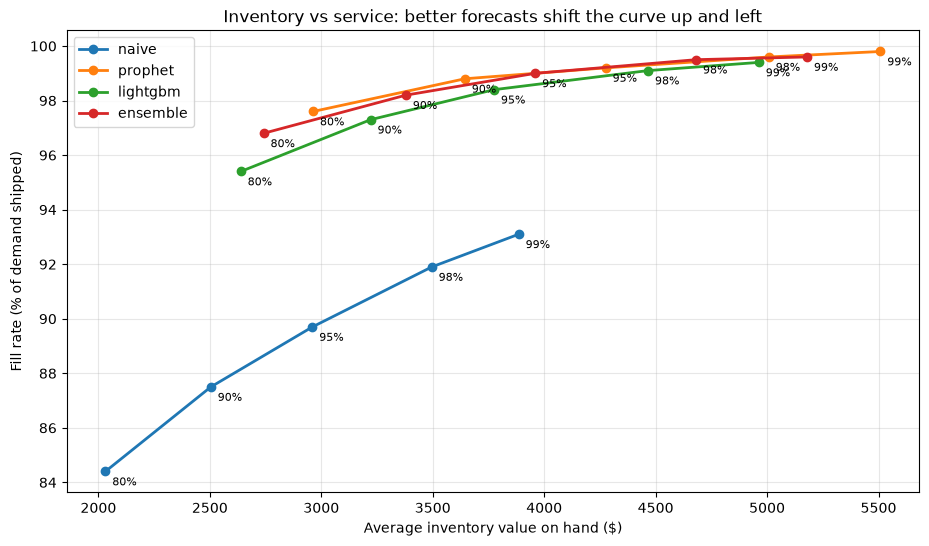

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
for model in MODELS:
    s = summary.loc[model]
    ax.plot(s["inventory_value"], s["fill_rate"], marker="o", linewidth=2, label=model)
    for sl, row in s.iterrows():
        ax.annotate(f"{sl:.0%}", (row["inventory_value"], row["fill_rate"]),
                    textcoords="offset points", xytext=(5, -10), fontsize=8)
ax.set_xlabel("Average inventory value on hand ($)")
ax.set_ylabel("Fill rate (% of demand shipped)")
ax.set_title("Inventory vs service: better forecasts shift the curve up and left")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## What a better forecast is worth

| Policy | Avg inventory | Fill rate | Stockout days |
|---|---:|---:|---:|
| Naive forecast @ 99% target | $3,886 | 93.1% | 114 |
| **Ensemble forecast @ 95% target** | **$3,960** | **99.0%** | **26** |
| Ensemble forecast @ 80% target | $2,741 | 96.8% | 75 |

- **About the same inventory, far better service:** 99.0% vs 93.1% fill rate, with 77% fewer stockout days.
- **Less inventory, still better service:** the ensemble beats the naive policy's best fill rate while holding 29% less inventory.
- Extra safety stock cannot rescue the naive forecast, because it is wrong in both directions:
  too high on beverages heading into winter, too low on promotions, holidays and winter-peaking products.